## 1. Setup

Define dependencies, paths, and reproducibility settings.
Colab runtime storage is temporary; persist final artifacts externally.


In [1]:
# %pip install -q numpy pandas matplotlib scikit-learn joblib shap gdown


In [17]:
from pathlib import Path
from copy import deepcopy
import random

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
import sklearn
import shap

from IPython.display import display
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import SGDRegressor
from sklearn.model_selection import ParameterGrid
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    root_mean_squared_error,
    r2_score,
)

In [3]:
# Classification replacements/additions:
#
# from sklearn.linear_model import SGDClassifier
# from sklearn.metrics import (
#     accuracy_score,
#     f1_score,
#     log_loss,
#     classification_report,
#     ConfusionMatrixDisplay,
# )


In [4]:
SEED = 42

random.seed(SEED)
np.random.seed(SEED)

In [5]:
# Run only when the prepared data are not already available.
!gdown --folder https://drive.google.com/drive/folders/1lFetK1YgncT5GPdLQFNrkuy8UWf-6881

Retrieving folder contents
Retrieving folder 14T5F5gwA0GGtPapainnN03f1IMhkXgec processed
Retrieving folder 1v372EjkxWn-8UdlhIvcPOS0ohwMXefZE pv_images
Processing file 1RFZRlUEIun3Z36gYpLClX8PRI4Og0Lql pv_images_test.csv
Processing file 1ZAqeFxVdPZu_uqfHT3Q7QRytm1CvbOnU pv_images_train.csv
Processing file 1pW98UOlS7Mh4LKHooN_1pzJjetJCnQFg pv_images_unknown.csv
Processing file 1hkMI_UN5FwmoSOfSXNuhz2zngOEjO-7k pv_images_validation.csv
Retrieving folder 1z994qLWlxE0mszwY1rLm8_1wQaso5gDB pv_time_series
Processing file 1DKNF0q9QHGBQSywBeNCC37bCEexxyWFq column_mapping.csv
Processing file 1bJlRxrYgcVEA1u383vq-F5g7E_lUQW3A pv_time_series_preprocessing.joblib
Processing file 1H5WyuYLz-Hye9SERAy1O3pu4grXmtLcJ pv_time_series_test_encoded.csv
Processing file 1ErXBDQHcCYa3aFv8rL0u7GTJkutuY5On pv_time_series_test_standardized.csv
Processing file 1IB0qv5K87J6MGmc8Q7SG-Q0lC745In1r pv_time_series_test.csv
Processing file 1nHbXSH4AxfpEwkwcqBfWOQVOI96SGaZQ pv_time_series_train_encoded.csv
Processing file

In [6]:
PROJECT_ROOT = Path.cwd()

CONFIG = {
    "data_dir": PROJECT_ROOT / "data" / "processed" / "pv_time_series",
    "output_dir": PROJECT_ROOT / "outputs" / "model_template",
    "random_state": SEED,
    "max_epochs": 500,
    "patience": 30
    }

CONFIG["output_dir"].mkdir(parents=True, exist_ok=True)

## 2. Data

Load prepared, unscaled chronological partitions.
Keep source files unchanged and reserve test for final evaluation.

In [7]:
train_data = pd.read_csv(CONFIG["data_dir"] / "pv_time_series_train.csv")
validation_data = pd.read_csv(CONFIG["data_dir"] / "pv_time_series_validation.csv")
test_data = pd.read_csv(CONFIG["data_dir"] / "pv_time_series_test.csv")

print(f"Train: {train_data.shape}")
print(f"Validation: {validation_data.shape}")
print(f"Test: {test_data.shape}")

Train: (4955, 25)
Validation: (1061, 25)
Test: (1061, 25)


## 3. Inputs and Target

Use only inputs available at prediction time.
Exclude future targets and non-input metadata.

In [8]:
TARGET = "target_power_t_plus_1"

NUMERIC_FEATURES = [
    "cosine_of_day",
    "cosine_of_hour",
    "air_temperature",
    "dewpoint",
    "wind_speed",
    "air_pressure",
    "solar_radiation",
    "pv_1_cosine_value_of_the_solar_incidence_angle",
    "pv_1_power",
    "pv_2_cosine_value_of_the_solar_incidence_angle",
    "pv_2_power",
    "pv_3_cosine_value_of_the_solar_incidence_angle",
    "pv_3_power",
    "pv_4_cosine_value_of_the_solar_incidence_angle",
    "pv_4_power",
    "pv_5_cosine_value_of_the_solar_incidence_angle",
    "pv_5_power",
]
CATEGORICAL_FEATURES = ["weather_condition"]
FEATURES = NUMERIC_FEATURES + CATEGORICAL_FEATURES

In [9]:
X_train = train_data.loc[:, FEATURES]
X_validation = validation_data.loc[:, FEATURES]
X_test = test_data.loc[:, FEATURES]

y_train = train_data[TARGET].to_numpy()
y_validation = validation_data[TARGET].to_numpy()
y_test = test_data[TARGET].to_numpy()

In [10]:
# Replace the target assignment above:
#
# TARGET = "target_class_t_plus_1"
#
# y_train = train_data[TARGET].to_numpy()
# y_validation = validation_data[TARGET].to_numpy()
# y_test = test_data[TARGET].to_numpy()
#
# CLASSES = np.unique(y_train)
#
# assert set(np.unique(y_validation)).issubset(set(CLASSES))
# assert set(np.unique(y_test)).issubset(set(CLASSES))


## 4. Preprocessing

Fit transformations on train only.
Scale numeric inputs and one-hot encode nominal categories.


In [11]:
preprocessor = ColumnTransformer(
    transformers=[
        ("numeric",StandardScaler(),NUMERIC_FEATURES),
        ("categorical",OneHotEncoder(handle_unknown="ignore",sparse_output=False),CATEGORICAL_FEATURES),

    ],
    remainder="drop",
    verbose_feature_names_out=False,
)

X_train_encoded = preprocessor.fit_transform(X_train)
X_validation_encoded = preprocessor.transform(X_validation)

feature_names = preprocessor.get_feature_names_out()

print(f"Transformed training shape: {X_train_encoded.shape}")

Transformed training shape: (4955, 26)


## 5. Model and Optimization

Define one estimator, its objective, and supported optimization settings.
Use regularization and validation-based stopping to limit overfitting.

In [14]:
MODEL_CONFIG = {
    "loss": "squared_error",
    "penalty": "l2",
    "alpha": 1e-4,
    "learning_rate": "constant",
    "eta0":1e-3,
    "fit_intercept": True,
    "shuffle": False,
    "random_state": SEED
}

optimization_settings = {
    "optimizer": "SGD",
    "loss": MODEL_CONFIG["loss"],
    "learning_rate_schedule": MODEL_CONFIG["learning_rate"],
    "initial_learning_rate": MODEL_CONFIG["eta0"],
    "regularization": MODEL_CONFIG["penalty"],
    "regularization_strength": MODEL_CONFIG["alpha"],
    "early_stopping_monitor": "validation_rmse",
    "patience": CONFIG["patience"],
}

display(pd.Series(optimization_settings))


,0
optimizer,SGD
loss,squared_error
learning_rate_schedule,constant
initial_learning_rate,0.001
regularization,l2
regularization_strength,0.0001
early_stopping_monitor,validation_rmse
patience,30


In [16]:
base_model = SGDRegressor(**MODEL_CONFIG)

base_model

SGDRegressor(eta0=0.001, learning_rate='constant', random_state=42,
             shuffle=False)

In [ ]:
# Replace MODEL_CONFIG and base_model:
#
# MODEL_CONFIG = {
#     "loss": "log_loss",
#     "penalty": "l2",
#     "alpha": 1e-4,
#     "learning_rate": "constant",
#     "eta0": 1e-3,
#     "fit_intercept": True,
#     "shuffle": False,
#     "random_state": SEED,
# }
#
# base_model = SGDClassifier(**MODEL_CONFIG)
#
# Use validation log loss as the stopping and tuning objective.


## 6. Training Function

Define epoch-wise training and validation-based early stopping.
This cell only defines the function; training runs during hyperparameter search.
Return the best validation checkpoint, not the last epoch.


In [19]:
def train_model(model, parameters):
    model = clone(model).set_params(**parameters)

    best_model = None
    best_rmse = np.inf
    best_epoch = 0
    epochs_without_improvement = 0

    records = []

    for epoch in range(1, CONFIG["max_epochs"] + 1):
        model.partial_fit(X_train_encoded, y_train)

        train_prediction = model.predict(X_train_encoded)
        validation_prediction = model.predict(X_validation_encoded)

        train_rmse = root_mean_squared_error(
            y_train, train_prediction
        )
        validation_rmse = root_mean_squared_error(
            y_validation, validation_prediction
        )

        records.append({
            "epoch": epoch,
            "train_rmse": train_rmse,
            "validation_rmse": validation_rmse,
        })

        if validation_rmse < best_rmse:
            best_rmse = validation_rmse
            best_epoch = epoch
            best_model = deepcopy(model)
            epochs_without_improvement = 0
        else:
            epochs_without_improvement += 1

        if epochs_without_improvement >= CONFIG["patience"]:
            break

    history = pd.DataFrame(records)

    return best_model, history, best_rmse, best_epoch


In [20]:
# Classification alternative: replace train_model with this function.
#
# from sklearn.metrics import f1_score
#
# CLASSES = np.unique(y_train)
#
#
# def train_model(model, parameters):
#     model = clone(model).set_params(**parameters)
#
#     best_model = None
#     best_f1 = -np.inf
#     best_epoch = 0
#     epochs_without_improvement = 0
#
#     records = []
#
#     for epoch in range(1, CONFIG["max_epochs"] + 1):
#         model.partial_fit(
#             X_train_encoded,
#             y_train,
#             classes=CLASSES,
#         )
#
#         train_prediction = model.predict(X_train_encoded)
#         validation_prediction = model.predict(X_validation_encoded)
#
#         train_f1 = f1_score(
#             y_train,
#             train_prediction,
#             labels=CLASSES,
#             average="macro",
#             zero_division=0,
#         )
#
#         validation_f1 = f1_score(
#             y_validation,
#             validation_prediction,
#             labels=CLASSES,
#             average="macro",
#             zero_division=0,
#         )
#
#         records.append({
#             "epoch": epoch,
#             "train_f1": train_f1,
#             "validation_f1": validation_f1,
#         })
#
#         if validation_f1 > best_f1:
#             best_f1 = validation_f1
#             best_epoch = epoch
#             best_model = deepcopy(model)
#             epochs_without_improvement = 0
#         else:
#             epochs_without_improvement += 1
#
#         if epochs_without_improvement >= CONFIG["patience"]:
#             break
#
#     history = pd.DataFrame(records)
#
#     return best_model, history, best_f1, best_epoch


## 7. Hyperparameter Search and Training

Search a small predefined parameter grid.
Train every combination with the same epoch limit and patience.
Select the checkpoint with the lowest validation RMSE across all trials.

Validation guides both stopping and selection; test remains untouched.


In [21]:
# Assumes base_model uses:
# penalty="l2", learning_rate="constant", and a fixed random_state.
# Built-in early stopping must be disabled; train_model handles stopping.

PARAM_GRID = {
    "eta0": [1e-4, 1e-3],
    "alpha": [1e-5, 1e-3],
}

search_records = []

selected_model = None
selected_history = None
selected_parameters = None
selected_epoch = None
selected_rmse = np.inf

parameter_combinations = list(ParameterGrid(PARAM_GRID))

for trial, parameters in enumerate(parameter_combinations, start=1):
    print(
        f"Trial {trial}/{len(parameter_combinations)}:",
        parameters,
    )

    model, history, validation_rmse, best_epoch = train_model(
        base_model,
        parameters,
    )

    search_records.append({
        "trial": trial,
        **parameters,
        "validation_rmse": validation_rmse,
        "best_epoch": best_epoch,
        "epochs_run": len(history),
    })

    print(
        f"  Epochs run: {len(history)} | "
        f"Best epoch: {best_epoch} | "
        f"Validation RMSE: {validation_rmse:.4f}"
    )

    if validation_rmse < selected_rmse:
        selected_rmse = validation_rmse
        selected_model = model
        selected_history = history
        selected_parameters = parameters.copy()
        selected_epoch = best_epoch

tuning_results = (
    pd.DataFrame(search_records)
    .sort_values("validation_rmse", kind="stable")
    .reset_index(drop=True)
)

display(tuning_results)

print("Selected parameters:", selected_parameters)
print("Selected epoch:", selected_epoch)
print("Selected validation RMSE:", selected_rmse)


Trial 1/4: {'alpha': 1e-05, 'eta0': 0.0001}
  Epochs run: 500 | Best epoch: 500 | Validation RMSE: 89.8900
Trial 2/4: {'alpha': 1e-05, 'eta0': 0.001}
  Epochs run: 82 | Best epoch: 52 | Validation RMSE: 88.4733
Trial 3/4: {'alpha': 0.001, 'eta0': 0.0001}
  Epochs run: 500 | Best epoch: 500 | Validation RMSE: 90.1705
Trial 4/4: {'alpha': 0.001, 'eta0': 0.001}
  Epochs run: 88 | Best epoch: 58 | Validation RMSE: 88.6333


,trial,alpha,eta0,validation_rmse,best_epoch,epochs_run
0,2,0.00001,0.0010,88.473290,52,82
1,4,0.00100,0.0010,88.633300,58,88
2,1,0.00001,0.0001,89.889959,500,500
3,3,0.00100,0.0001,90.170457,500,500


Selected parameters: {'alpha': 1e-05, 'eta0': 0.001}
Selected epoch: 52
Selected validation RMSE: 88.47328972810547


In [22]:
# Keep PARAM_GRID and replace the search block:
#
# search_records = []
#
# selected_model = None
# selected_history = None
# selected_parameters = None
# selected_epoch = None
# selected_f1 = -np.inf
#
# parameter_combinations = list(ParameterGrid(PARAM_GRID))
#
# for trial, parameters in enumerate(parameter_combinations, start=1):
#     print(
#         f"Trial {trial}/{len(parameter_combinations)}:",
#         parameters,
#     )
#
#     model, history, validation_f1, best_epoch = train_model(
#         base_model,
#         parameters,
#     )
#
#     search_records.append({
#         "trial": trial,
#         **parameters,
#         "validation_f1": validation_f1,
#         "best_epoch": best_epoch,
#         "epochs_run": len(history),
#     })
#
#     print(
#         f"  Epochs run: {len(history)} | "
#         f"Best epoch: {best_epoch} | "
#         f"Validation macro F1: {validation_f1:.4f}"
#     )
#
#     if validation_f1 > selected_f1:
#         selected_f1 = validation_f1
#         selected_model = model
#         selected_history = history
#         selected_parameters = parameters.copy()
#         selected_epoch = best_epoch
#
# tuning_results = (
#     pd.DataFrame(search_records)
#     .sort_values(
#         "validation_f1",
#         ascending=False,
#         kind="stable",
#     )
#     .reset_index(drop=True)
# )
#
# display(tuning_results)
#
# print("Selected parameters:", selected_parameters)
# print("Selected epoch:", selected_epoch)
# print("Selected validation macro F1:", selected_f1)
#
# Update the Markdown: maximize validation macro F1.


## 8. Training Diagnostics

Inspect the selected run's learning curves and train–validation gap.
Check whether validation performance was still improving at the epoch limit.
A train–validation gap may reflect overfitting, temporal shift, or both.


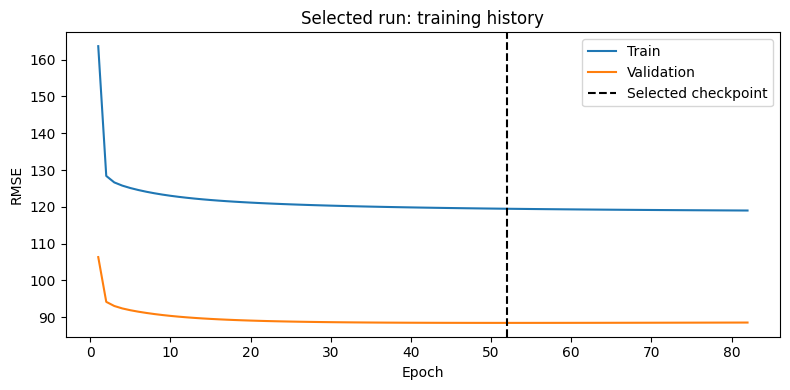

In [23]:
fig, ax = plt.subplots(figsize=(8, 4))

ax.plot(
    selected_history["epoch"],
    selected_history["train_rmse"],
    label="Train",
)

ax.plot(
    selected_history["epoch"],
    selected_history["validation_rmse"],
    label="Validation",
)

ax.axvline(
    selected_epoch,
    color="black",
    linestyle="--",
    label="Selected checkpoint",
)

ax.set(
    xlabel="Epoch",
    ylabel="RMSE",
    title="Selected run: training history",
)

ax.legend()
plt.tight_layout()
plt.show()


In [24]:
# In the plot above, replace:
#
# "train_rmse" -> "train_f1"
# "validation_rmse" -> "validation_f1"
# ylabel="RMSE" -> ylabel="Macro F1"


In [26]:
selected_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", selected_model),
])

# Both steps are already fitted. Do not call fit() again.

train_prediction = selected_pipeline.predict(X_train)
validation_prediction = selected_pipeline.predict(X_validation)

train_rmse = root_mean_squared_error(y_train, train_prediction)
validation_rmse = root_mean_squared_error(y_validation, validation_prediction)

print("Train RMSE:", train_rmse)
print("Validation RMSE:", validation_rmse)
print("Validation − train RMSE:", validation_rmse - train_rmse)


Train RMSE: 119.48217838920327
Validation RMSE: 88.47328972810547
Validation − train RMSE: -31.0088886610978


In [27]:
# Keep pipeline construction and predictions.
# Replace the metric calculations and prints:
#
# train_f1 = f1_score(
#     y_train,
#     train_prediction,
#     labels=CLASSES,
#     average="macro",
#     zero_division=0,
# )
#
# validation_f1 = f1_score(
#     y_validation,
#     validation_prediction,
#     labels=CLASSES,
#     average="macro",
#     zero_division=0,
# )
#
# print("Train macro F1:", train_f1)
# print("Validation macro F1:", validation_f1)
# print("Train − validation macro F1:", train_f1 - validation_f1)


## 9. Validation Evaluation

Review validation metrics and errors before freezing the experiment.
Do not use test results to revise model settings.


In [28]:
validation_metrics = pd.DataFrame([{
    "split": "validation",
    "MAE": mean_absolute_error(
        y_validation,
        validation_prediction,
    ),
    "RMSE": root_mean_squared_error(
        y_validation,
        validation_prediction,
    ),
    "R2": r2_score(
        y_validation,
        validation_prediction,
    ),
}])

display(validation_metrics)


,split,MAE,RMSE,R2
0,validation,57.139844,88.47329,0.960077


In [29]:
# Replace validation_metrics:
#
# validation_metrics = pd.DataFrame([{
#     "split": "validation",
#     "accuracy": accuracy_score(
#         y_validation,
#         validation_prediction,
#     ),
#     "macro_f1": f1_score(
#         y_validation,
#         validation_prediction,
#         labels=CLASSES,
#         average="macro",
#         zero_division=0,
#     ),
# }])
#
# display(validation_metrics)


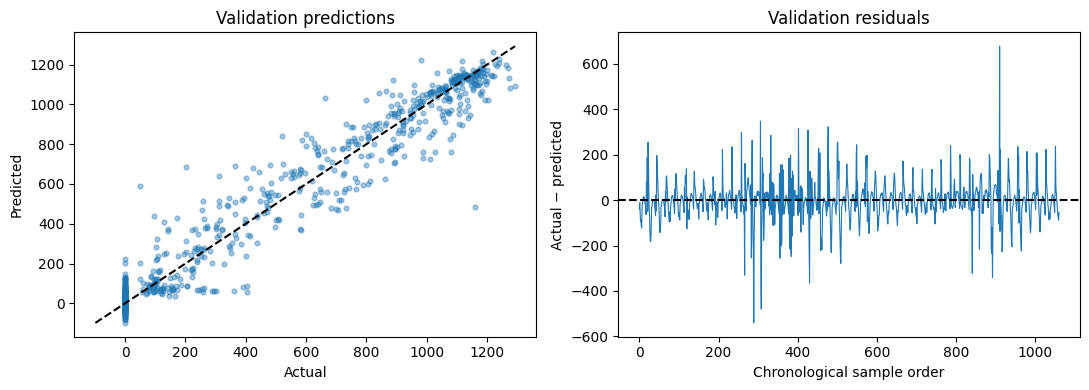

In [30]:
validation_actual = np.asarray(y_validation)
validation_residual = validation_actual - validation_prediction

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].scatter(
    validation_actual,
    validation_prediction,
    s=12,
    alpha=0.4,
)

lower = min(validation_actual.min(), validation_prediction.min())
upper = max(validation_actual.max(), validation_prediction.max())

axes[0].plot([lower, upper], [lower, upper], "k--")
axes[0].set(
    xlabel="Actual",
    ylabel="Predicted",
    title="Validation predictions",
)

axes[1].plot(
    np.arange(len(validation_residual)),
    validation_residual,
    linewidth=0.8,
)

axes[1].axhline(0, color="black", linestyle="--")
axes[1].set(
    xlabel="Chronological sample order",
    ylabel="Actual − predicted",
    title="Validation residuals",
)

plt.tight_layout()
plt.show()


In [31]:
# Replace the regression error plots:
#
# print(
#     classification_report(
#         y_validation,
#         validation_prediction,
#         labels=CLASSES,
#         zero_division=0,
#     )
# )
#
# ConfusionMatrixDisplay.from_predictions(
#     y_validation,
#     validation_prediction,
#     labels=CLASSES,
#     cmap="Blues",
# )
#
# plt.tight_layout()
# plt.show()


## 10. Final Evaluation

Freeze preprocessing, hyperparameters, and the selected checkpoint.
Evaluate once on test without refitting or further tuning.


In [35]:
final_parameters = selected_model.get_params()

print("Selected search parameters:", selected_parameters)
print("Selected checkpoint:", selected_epoch)

test_prediction = selected_pipeline.predict(X_test)

test_metrics = pd.DataFrame([{
    "split": "test",
    "MAE": mean_absolute_error(y_test, test_prediction),
    "RMSE": root_mean_squared_error(y_test, test_prediction),
    "R2": r2_score(y_test, test_prediction),
}])

display(test_metrics)


Selected search parameters: {'alpha': 1e-05, 'eta0': 0.001}
Selected checkpoint: 52


,split,MAE,RMSE,R2
0,test,86.719626,133.441226,0.905303


In [36]:
# Keep final_parameters, prints, and test_prediction.
# Replace test_metrics:
#
# test_metrics = pd.DataFrame([{
#     "split": "test",
#     "accuracy": accuracy_score(y_test, test_prediction),
#     "macro_f1": f1_score(
#         y_test,
#         test_prediction,
#         labels=CLASSES,
#         average="macro",
#         zero_division=0,
#     ),
# }])
#
# display(test_metrics)
#
# print(
#     classification_report(
#         y_test,
#         test_prediction,
#         labels=CLASSES,
#         zero_division=0,
#     )
# )


In [37]:
test_predictions = pd.DataFrame({
    "sample_index": X_test.index.to_numpy(),
    "actual": np.asarray(y_test),
    "prediction": test_prediction,
    "residual": np.asarray(y_test) - test_prediction,
})

display(test_predictions.head())


,sample_index,actual,prediction,residual
0,0,0.0,27.547512,-27.547512
1,1,0.0,22.648067,-22.648067
2,2,0.0,7.560674,-7.560674
3,3,0.0,-3.061237,3.061237
4,4,0.0,-18.910883,18.910883


In [38]:
# Replace test_predictions:
#
# test_predictions = pd.DataFrame({
#     "sample_index": X_test.index.to_numpy(),
#     "actual": np.asarray(y_test),
#     "prediction": test_prediction,
# })
#
# display(test_predictions.head())


## 11. Model Interpretation

Explain validation predictions using a training background.
Attributions refer to transformed features and are not causal effects.
*italicized text*

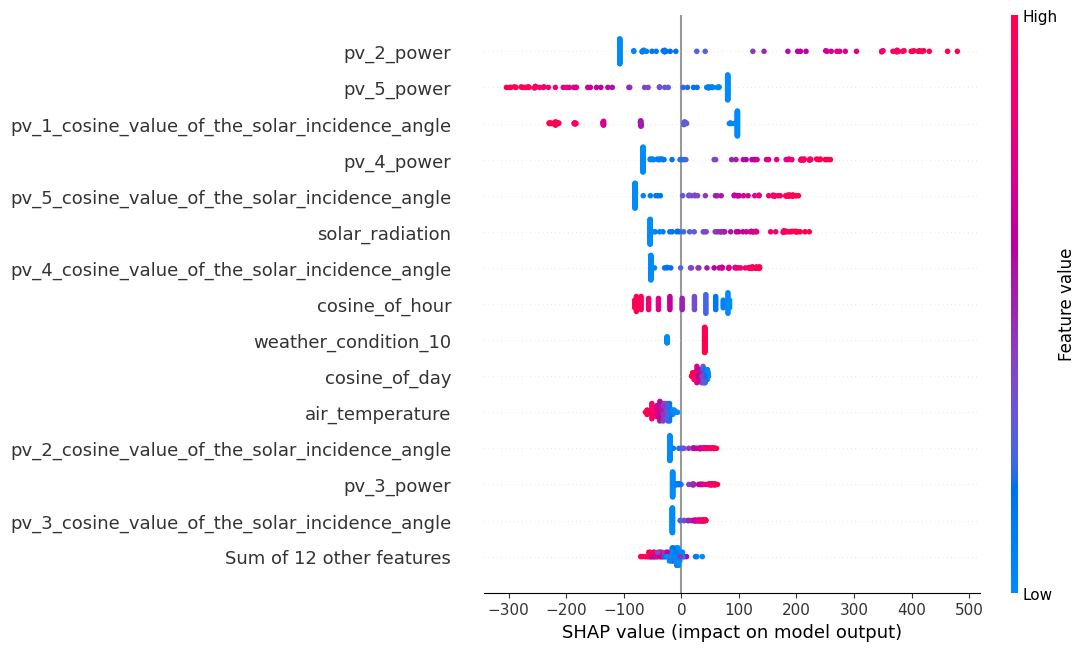

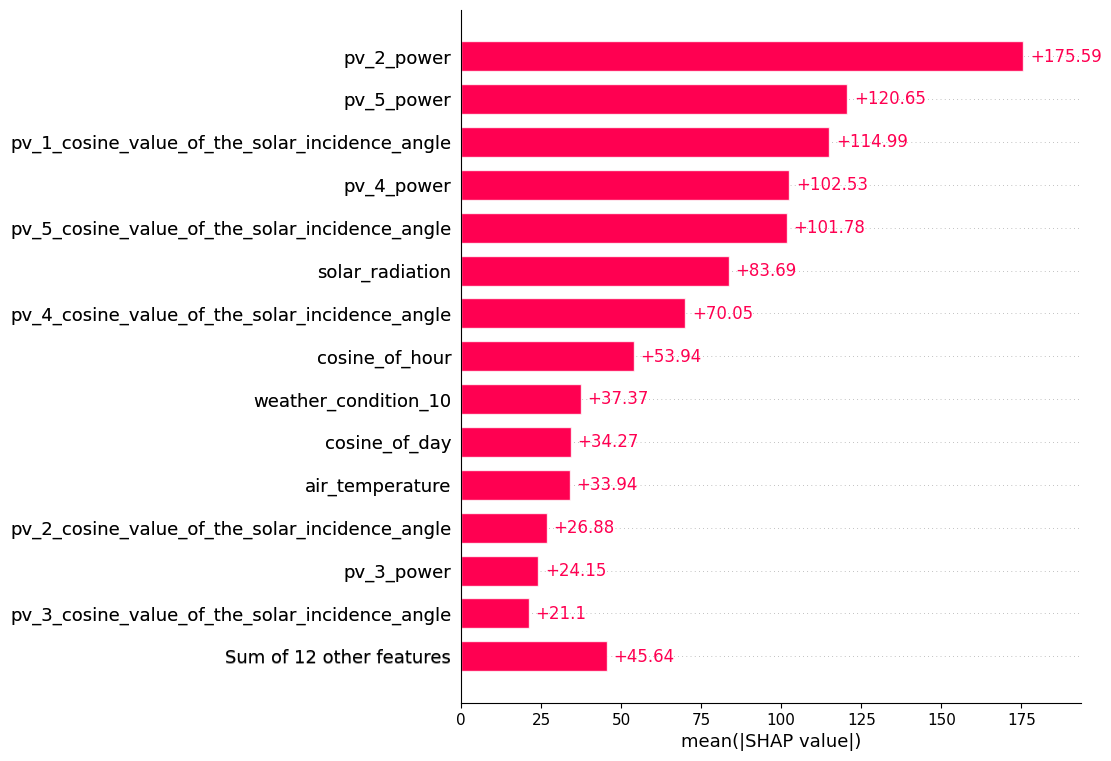

In [32]:
background = shap.sample(
    X_train_encoded,
    nsamples=min(100, X_train_encoded.shape[0]),
    random_state=SEED,
)

X_explain = shap.sample(
    X_validation_encoded,
    nsamples=min(100, X_validation_encoded.shape[0]),
    random_state=SEED,
)

explainer = shap.Explainer(
    selected_model.predict,
    background,
    algorithm="permutation",
    feature_names=list(feature_names),
    seed=SEED,
)

shap_values = explainer(
    X_explain,
    max_evals=5 * (2 * X_explain.shape[1] + 1),
)

shap.plots.beeswarm(shap_values, max_display=15)
shap.plots.bar(shap_values, max_display=15)


In [33]:
# Requires predict_proba, e.g. SGDClassifier(loss="log_loss").
# Selection still uses macro F1; SHAP explains a class probability.
#
# Keep background and X_explain.
# Replace the explainer and plotting block:
#
# EXPLAIN_CLASS = "high"  # Set an actual class label.
#
# class_index = list(selected_model.classes_).index(EXPLAIN_CLASS)
#
#
# def predict_class_probability(X):
#     return selected_model.predict_proba(X)[:, class_index]
#
#
# explainer = shap.Explainer(
#     predict_class_probability,
#     background,
#     algorithm="permutation",
#     feature_names=list(feature_names),
#     seed=SEED,
# )
#
# shap_values = explainer(
#     X_explain,
#     max_evals=5 * (2 * X_explain.shape[1] + 1),
# )
#
# shap.plots.beeswarm(shap_values, max_display=15)
# shap.plots.bar(shap_values, max_display=15)


In [34]:
shap_importance = (
    pd.DataFrame({
        "feature": feature_names,
        "mean_absolute_shap": np.abs(shap_values.values).mean(axis=0),
    })
    .sort_values("mean_absolute_shap", ascending=False)
    .reset_index(drop=True)
)

display(shap_importance.head(15))


,feature,mean_absolute_shap
0,pv_2_power,175.594462
1,pv_5_power,120.647786
2,pv_1_cosine_value_of_the_solar_incidence_angle,114.991304
3,pv_4_power,102.525866
4,pv_5_cosine_value_of_the_solar_incidence_angle,101.777963
5,solar_radiation,83.685535
6,pv_4_cosine_value_of_the_solar_incidence_angle,70.047265
7,cosine_of_hour,53.937835
8,weather_condition_10,37.373931
9,cosine_of_day,34.266351


## 12. Artifacts

Save the evaluated pipeline, search settings, metrics, and diagnostics.
Reload only trusted artifacts and verify prediction consistency.


In [38]:
CONFIG["output_dir"].mkdir(parents=True, exist_ok=True)

artifact = {
    "pipeline": selected_pipeline,
    "model_class": type(selected_model).__name__,
    "feature_columns": FEATURES,
    "numeric_features": NUMERIC_FEATURES,
    "categorical_features": CATEGORICAL_FEATURES,
    "target_column": TARGET,
    "target_scaled": False,
    "input_format": "raw, unencoded, unscaled features",
    "parameter_grid": PARAM_GRID,
    "selected_parameters": selected_parameters,
    "estimator_parameters": final_parameters,
    "selected_epoch": selected_epoch,
    "selection_metric": "validation_rmse",
    "config": CONFIG,
    "versions": {
        "numpy": np.__version__,
        "pandas": pd.__version__,
        "scikit_learn": sklearn.__version__,
        "shap": shap.__version__,
        "joblib": joblib.__version__,
    },
}

model_path = CONFIG["output_dir"] / "model_pipeline.joblib"

joblib.dump(artifact, model_path)

tuning_results.to_csv(
    CONFIG["output_dir"] / "tuning_results.csv",
    index=False,
)

selected_history.to_csv(
    CONFIG["output_dir"] / "training_history.csv",
    index=False,
)

pd.concat(
    [validation_metrics, test_metrics],
    ignore_index=True,
).to_csv(
    CONFIG["output_dir"] / "metrics.csv",
    index=False,
)

test_predictions.to_csv(
    CONFIG["output_dir"] / "test_predictions.csv",
    index=False,
)

shap_importance.to_csv(
    CONFIG["output_dir"] / "shap_importance.csv",
    index=False,
)

print("Saved to:", CONFIG["output_dir"])


In [ ]:
# Before saving, replace:
#
# "selection_metric": "validation_rmse",
#
# with:
#
# "selection_metric": "validation_macro_f1",
# "class_labels": selected_model.classes_.tolist(),


In [ ]:
loaded_artifact = joblib.load(model_path)

new_observations = X_test.loc[:,loaded_artifact["feature_columns"],
].head(5)

reloaded_prediction = loaded_artifact["pipeline"].predict(new_observations)

np.testing.assert_allclose(
    reloaded_prediction,
    test_prediction[:len(new_observations)],
)

print("Reload check passed.")
print(reloaded_prediction)


In [ ]:
# Replace assert_allclose:
#
# np.testing.assert_array_equal(
#     reloaded_prediction,
#     test_prediction[:len(new_observations)],
# )